### Análise 1 — Evolução dos Atendimentos por Bairro (2022–2024)

Pergunta: Será que analisando o numero de atendimentos ao longo dos anos por diferentes opticas é possivel chegar em alguma conclusão significativa?

Esta análise tem como objetivo comparar a quantidade de atendimentos realizados pela Defesa Civil do Recife nos diferentes bairros da cidade, considerando os anos de 2022, 2023 e 2024.

A partir dos dados armazenados no banco PostgreSQL, serão identificados os bairros com maior número de atendimentos, além daqueles que apresentaram os maiores aumentos e reduções ao longo desse período. 

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine
from dotenv import load_dotenv

In [3]:
load_dotenv("../.env")

usuario = os.getenv("DB_USER")
senha = os.getenv("DB_PASSWORD")
host = os.getenv("DB_HOST")
porta = os.getenv("DB_PORT")
banco = os.getenv("DB_NAME")

engine = create_engine(
    f"postgresql+psycopg2://{usuario}:{senha}@{host}:{porta}/{banco}"
)

with engine.connect() as conexao:
    print("Conexão realizada com sucesso!")

Conexão realizada com sucesso!


### Consultas

Primeiramente, vai ser montanda as tabelas necessarias para relacionar os bairros e a quantidade de atendimentos por ano.

Segundamente, serão calculadas as diferenças absolutas e percentuais no número de atendimentos por bairro entre 2022 e 2024, permitindo identificar quais localidades apresentaram crescimento ou redução no período.

In [10]:
# mesma consulta salva em analises/analise_1_evolucao_bairros.sql
consulta = open("../analises/analise_1_evolucao_bairros.sql", encoding="utf-8").read()

df_atendimentos = pd.read_sql(consulta, con=engine)

display(df_atendimentos.head(9))

,bairro,ano,total_atendimentos
0,Aflitos,2022,1
1,Aflitos,2023,17
2,Aflitos,2024,14
3,Afogados,2022,65
4,Afogados,2023,88
5,Afogados,2024,113
6,Agua Fria,2022,3601
7,Agua Fria,2023,2917
8,Agua Fria,2024,3114


In [ ]:
df_evolucao = df_atendimentos.pivot_table(
    index="bairro",
    columns="ano",
    values="total_atendimentos",
    aggfunc="sum",# soma a partir dos parametros acima
    fill_value=0 # os nulls viram zero pra soma ocorrer
)

df_evolucao.columns = df_evolucao.columns.astype(str)
# preferido transformar em strings pra consultas futuras

display(df_evolucao.head(10))

ano,2022,2023,2024
bairro,,,
Aflitos,1,17,14
Afogados,65,88,113
Agua Fria,3601,2917,3114
Alto Da Bela Vista,40,0,0
Alto Do Eucalipto,32,1,0
Alto Do Mandu,6,1,19
Alto Do Maracana,0,0,4
Alto Jose Bonifacio,3226,2863,2291
Alto Jose Do Pinho,74,4,6


o output das celulas acima são um teste so pra saber se deu certo a montagem das tabelas

In [6]:
df_evolucao["variacao_absoluta"] = (
    df_evolucao["2024"] - df_evolucao["2022"]
)

df_evolucao["variacao 2022-2023"] = (
    df_evolucao["2023"] - df_evolucao["2022"]
)

df_evolucao["variacao 2023-2024"] = (
    df_evolucao["2024"] - df_evolucao["2023"]
)

df_evolucao["variacao_percentual_absoluta"] = (
    (df_evolucao["variacao_absoluta"] / df_evolucao["2022"].replace(0, float("nan"))) * 100
).round(2)

Obs: a variação absoluta foi representada como a variação entre o numero de atendimentos entre 2022 e 2024

A partir das variações calculadas, serão identificados os dez bairros com os maiores aumentos e os dez com as maiores reduções absolutas no número de atendimentos.

Essa comparação permitirá observar quais bairros tiveram as mudanças mais expressivas entre o início e o fim do período de anos analisado.

In [7]:
maiores_aumentos = df_evolucao.sort_values(
    by="variacao_absoluta",
    ascending=False
).head(20)

maiores_reducoes = df_evolucao.sort_values(
    by="variacao_absoluta",
    ascending=True
).head(20)

print("Bairros com maiores aumentos:")
display(maiores_aumentos)

print("Bairros com maiores reduções:")
display(maiores_reducoes)

Bairros com maiores aumentos:


ano,2022,2023,2024,variacao_absoluta,variacao 2022-2023,variacao 2023-2024,variacao_percentual_absoluta
bairro,,,,,,,
Varzea,3674,2508,5257,1583,-1166,2749,43.09
Dois Unidos,8412,8654,9702,1290,242,1048,15.34
Dois Irmaos,679,1204,1429,750,525,225,110.46
Morro Da Conceicao,529,426,1212,683,-103,786,129.11
Macaxeira,1725,2949,2316,591,1224,-633,34.26
Alto Santa Terezinha,285,621,698,413,336,77,144.91
Boa Vista,338,365,707,369,27,342,109.17
Imbiribeira,95,312,438,343,217,126,361.05
Sao Jose,152,1683,411,259,1531,-1272,170.39


Bairros com maiores reduções:


ano,2022,2023,2024,variacao_absoluta,variacao 2022-2023,variacao 2023-2024,variacao_percentual_absoluta
bairro,,,,,,,
Nova Descoberta,11518,9766,7557,-3961,-1752,-2209,-34.39
Cohab,14220,11554,12060,-2160,-2666,506,-15.19
Guabiraba,3795,1974,2205,-1590,-1821,231,-41.90
Corrego Do Jenipapo,1267,1544,1,-1266,277,-1543,-99.92
Passarinho,2949,2135,1959,-990,-814,-176,-33.57
Alto Jose Bonifacio,3226,2863,2291,-935,-363,-572,-28.98
Barro,2337,1264,1485,-852,-1073,221,-36.46
Linha Do Tiro,3558,2495,2847,-711,-1063,352,-19.98
Jordao,3221,2723,2580,-641,-498,-143,-19.90


Obs: Nessa tabela já da pra perceber discrepâncias entre a quantidade de atendimentos anuais, o bairro do Corrego do Jenipapo é o caso mais drastico desse tipo, por que será que no ano de 2024 so teve 1 atendimento registrado nos dados da defesa civil?

Evolução geral dos atendimentos

O gráfico a seguir apresenta a quantidade total de atendimentos por ano, considerando os bairros identificados na base de dados.

Essa visualização permite observar se houve crescimento ou redução no volume geral de atendimentos entre 2022 e 2024.

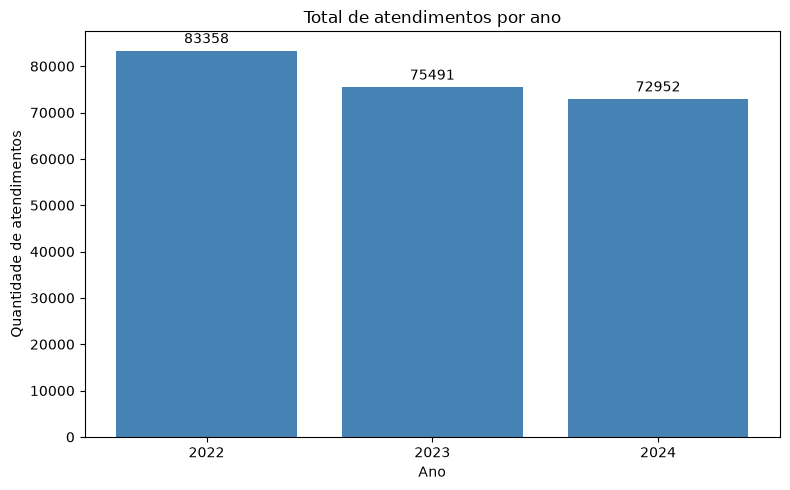

In [8]:
total_por_ano = df_evolucao[["2022", "2023", "2024"]].sum()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    total_por_ano.index,
    total_por_ano.values,
    color="steelblue"
)

plt.bar_label(barras, padding=3)

plt.title("Total de atendimentos por ano em cada bairro")
plt.xlabel("Ano")
plt.ylabel("Quantidade de atendimentos")

plt.tight_layout()
plt.show()

Pelo gráfico acima, é possível notar que o ano de 2022, entre os analisados, foi o que apresentou o maior número de atendimentos documentados, fenômeno esse que possivelmente está relacionado às chuvas extremas que atingiram a Região Metropolitana do Recife em meados de 2022 e aos seus desdobramentos.

Comparação dos bairros usando a variação absoluta como referencial

Os gráficos gerados abaixo destacam os bairros que apresentaram as maiores mudanças absolutas no número de atendimentos entre 2022 e 2024, separando os aumentos das reduções.

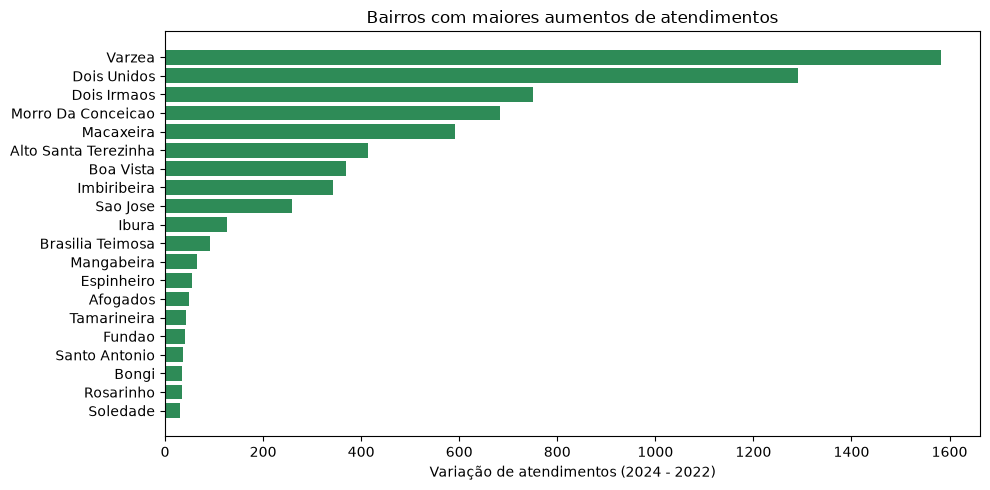

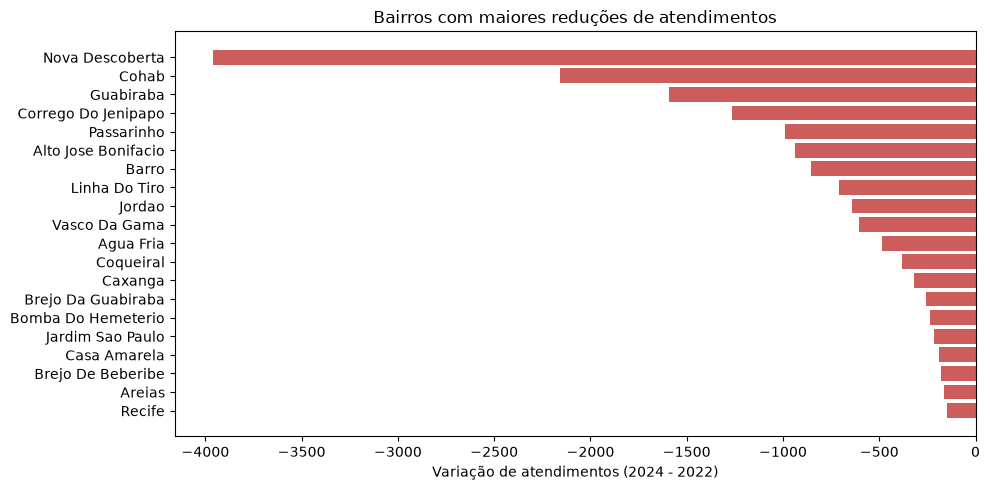

In [9]:
aumentos = maiores_aumentos[
    maiores_aumentos["variacao_absoluta"] > 0
].sort_values("variacao_absoluta")

reducoes = maiores_reducoes[
    maiores_reducoes["variacao_absoluta"] < 0
].sort_values("variacao_absoluta", ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(
    aumentos.index,
    aumentos["variacao_absoluta"],
    color="seagreen"
)

plt.title("Bairros com maiores aumentos de atendimentos")
plt.xlabel("Variação de atendimentos (2024 - 2022)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.barh(
    reducoes.index,
    reducoes["variacao_absoluta"],
    color="indianred"
)

plt.title("Bairros com maiores reduções de atendimentos")
plt.xlabel("Variação de atendimentos (2024 - 2022)")
plt.tight_layout()
plt.show()

### Insights

A Pergunta incial foi : Será que analisando o numero de atendimentos ao longo dos anos por diferentes opticas é possivel chegar em alguma conclusão significativa?

A resposta pra essa pergunta seria sim, ja que foi encontrados dados curiosos e outros que são possíveis relacionar com acontecimentos locais, entre eles acho que a analise de três bairros especificos faz-se necessario:

O bairro da Várzea lidera o gráfico de aumento de atendimentos, passando de 3.674 registros em 2022 para 5.257 em 2024, um crescimento de aproximadamente 43,09%. Esse aumento foi especialmente expressivo entre 2023 e 2024, quando o número de atendimentos mais que dobrou.

Esse comportamento pode estar relacionado aos problemas de drenagem e alagamentos presentes em determinadas áreas do bairro, O bairro é conhecido por ter pontos recorrentes de alagamento, fato esse identificado pelo estudo apresentado no XV Encontro Nacional de Águas Urbanas. 

Além disso, em junho de 2024, a estação pluviométrica da Várzea registrou 154,3 mm de chuva em 24 horas, o que pode ter contribuído para o aumento das ocorrências, notícia documentada pelo Diario de Pernambuco.

Já o Bairro de Nova Descoberta apresenta redução constante de atedimentos ao passar dos anos. No final de 2022, Nova Descoberta recebeu investimentos em obras de contenção de encostas e drenagem. Apesar de poder existir uma relação entre essas obras e a redução de determinadas situações de risco, não é possivel afirmar com certeza esse fato.

Outro caso que chama atenção é Córrego do Jenipapo, que passou de 1.544 registros em 2023 para apenas 1 em 2024. Uma Disparidade gigante, qual será a causa, será a falta de documentação sobre ou a realmente não existencia de ocorrências, muito provavelmente é a primeira opção mas o tópico ainda não tem causa definida.

### Fontes

https://files.abrhidro.org.br/Eventos/Trabalhos/238/XV-ENAU0125-1-0-20240801-102239.pdf

https://www.diariodepernambuco.com.br/noticia/vidaurbana/2024/06/recife-teve-o-maior-volume-de-chuva-em-24h-desde-maio-de-2022.html

https://www.diariodepernambuco.com.br/noticia/vidaurbana/2022/11/prefeitura-do-recife-avanca-com-obras-de-contencao-de-encosta-em-nova.html